# Installing and Importing libraries

In [5]:
%pip install tensorflow matplotlib seaborn scikit-learn

  Using cached tensorflow-2.22.0rc0-cp314-cp314-win_amd64.whl.metadata (4.6 kB)
Using cached tensorflow-2.22.0rc0-cp314-cp314-win_amd64.whl (384.1 MB)
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an OSError: [WinError 32] The process cannot access the file because it is being used by another process: 'c:\\Users\\grace\\AppData\\Local\\Python\\pythoncore-3.14-64\\Lib\\site-packages\\tensorflow\\python\\eager\\polymorphic_function\\concrete_function.py'
Consider using the `--user` option or check the permissions.



In [3]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.models import Model

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

# Dataset Path

In [23]:
import zipfile

zip_path = r"C:\Users\grace\Downloads\archive (1).zip"
extract_path = r"C:\Users\grace\Downloads\PlantVillage"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed")

Extraction completed


In [24]:
import os

print(os.listdir(r"C:\Users\grace\Downloads\PlantVillage"))

['plantvillage dataset']


In [25]:
import os

print(os.listdir(r"C:\Users\grace\Downloads\PlantVillage\plantvillage dataset"))

['color', 'grayscale', 'segmented']


In [26]:
import os

dataset_path = r"C:\Users\grace\Downloads\PlantVillage\plantvillage dataset\color"

print(os.path.exists(dataset_path))
print(os.listdir(dataset_path)[:5])

True
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


# Data Augmentation

In [29]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    shear_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)


# Training and Validating Data

In [56]:
train_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=(128,128),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

validation_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=(128,128),
    batch_size=32,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

Found 43456 images belonging to 38 classes.
Found 10849 images belonging to 38 classes.


# Class Names

In [30]:
class_names = list(train_generator.class_indices.keys())

print(class_names)

['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Sp

# Visualising sample images

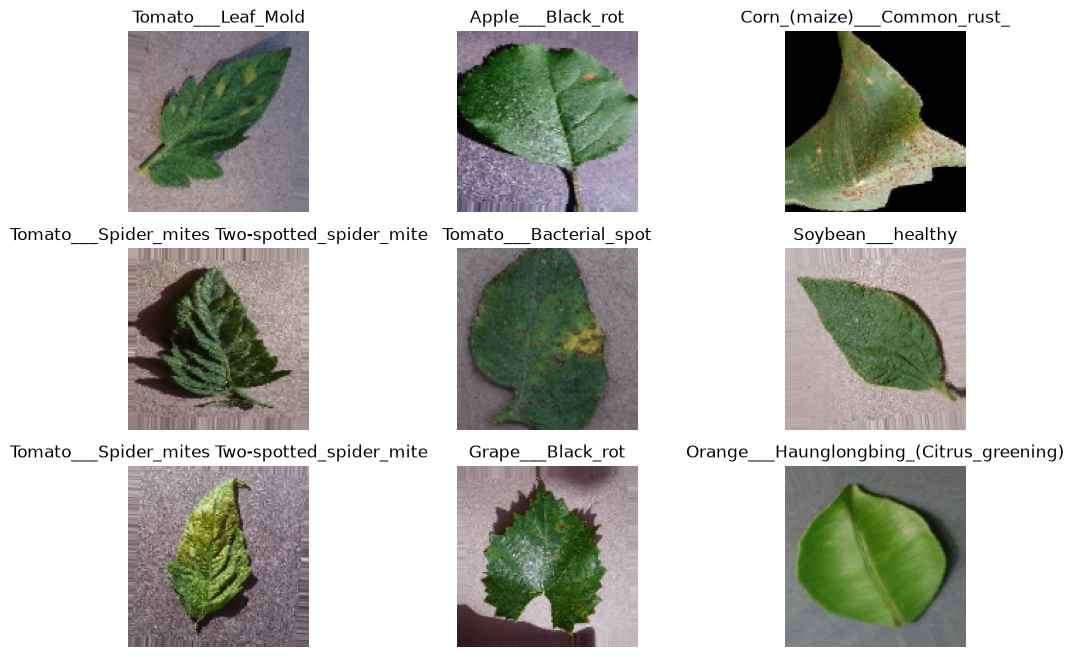

In [57]:
images, labels = next(train_generator)

plt.figure(figsize=(12,8))

for i in range(9):

    plt.subplot(3,3,i+1)

    plt.imshow(images[i])

    plt.title(
        class_names[
            np.argmax(labels[i])
        ]
    )

    plt.axis("off")

plt.show()

# Model

In [62]:
# build the model using EfficientNetB0 as the base model
base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(128,128,3)
)

base_model.trainable = False

x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dropout(0.3)(x)

x = Dense(
    256,
    activation='relu'
)(x)

x = Dropout(0.3)(x)

outputs = Dense(
    train_generator.num_classes,
    activation='softmax'
)(x)

model = Model(
    inputs=base_model.input,
    outputs=outputs
)
print("Model built successfully.")

Model built successfully.


In [64]:
# compile the model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully.")


Model compiled successfully.


In [66]:
# callbacks
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "best_model.keras",
    monitor='val_accuracy',
    save_best_only=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    verbose=1
)
print("Callbacks set up successfully.")


Callbacks set up successfully.


In [67]:
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=10,
    callbacks=[
        early_stop,
        checkpoint,
        reduce_lr
    ]
)

Epoch 1/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 573s 412ms/step - accuracy: 0.0994 - loss: 3.3815 - val_accuracy: 0.0987 - val_loss: 3.3471 - learning_rate: 0.0010
Epoch 2/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 772s 569ms/step - accuracy: 0.0998 - loss: 3.3643 - val_accuracy: 0.0987 - val_loss: 3.3453 - learning_rate: 0.0010
Epoch 3/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1103s 813ms/step - accuracy: 0.0996 - loss: 3.3622 - val_accuracy: 0.1015 - val_loss: 3.3516 - learning_rate: 0.0010
Epoch 4/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - accuracy: 0.0980 - loss: 3.3591
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 501s 369ms/step - accuracy: 0.0980 - loss: 3.3591 - val_accuracy: 0.1015 - val_loss: 3.3489 - learning_rate: 0.0010
Epoch 5/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 603s 444ms/step - accuracy: 0.0992 - loss: 3.3556 - val_accuracy: 0.1015 - val_loss: 3.3432 - learning_rate: 2.0000e-04
Epoch 6/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 685s 50

The CNN model exhibited poor learning performance throughout training. Training accuracy remained around 10%, while validation accuracy stabilized at approximately 10.15%. Since these values are close to what would be expected from random guessing, the model failed to learn meaningful patterns from the PlantVillage images. Additionally, both training and validation losses decreased only marginally across the ten epochs, indicating limited optimization progress. The similar values between training and validation performance suggest underfitting rather than overfitting. Potential causes include incorrect label encoding, dataset preprocessing issues, inadequate feature extraction capability, or an unsuitable network architecture. Future improvements may involve verifying data preprocessing steps, ensuring correct label mapping, and employing transfer learning models such as EfficientNetB0 or MobileNetV2, which have demonstrated strong performance on plant disease classification tasks.

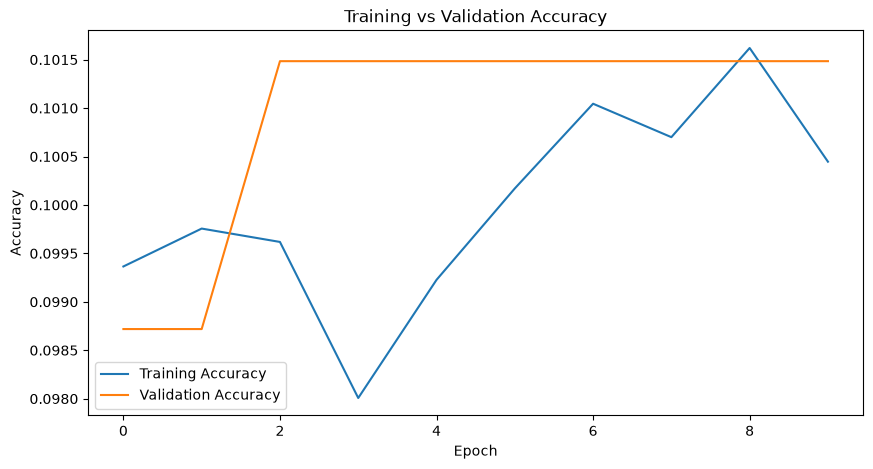

In [68]:
plt.figure(figsize=(10,5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

he training and validation accuracy curves remained nearly flat throughout the training process. Training accuracy fluctuated around 10%, while validation accuracy stabilized at approximately 10.15%. The close proximity of the two curves indicates that the model did not suffer from overfitting. However, the consistently low accuracy values suggest severe underfitting, meaning the model was unable to learn meaningful features from the PlantVillage image dataset. Since the accuracy remained close to the level expected from random guessing, further investigation of data preprocessing, label encoding, and model architecture is required. The results indicate that the current CNN configuration is inadequate for effective plant disease classification and may benefit from transfer learning approaches such as MobileNetV2, ResNet50, or EfficientNetB0

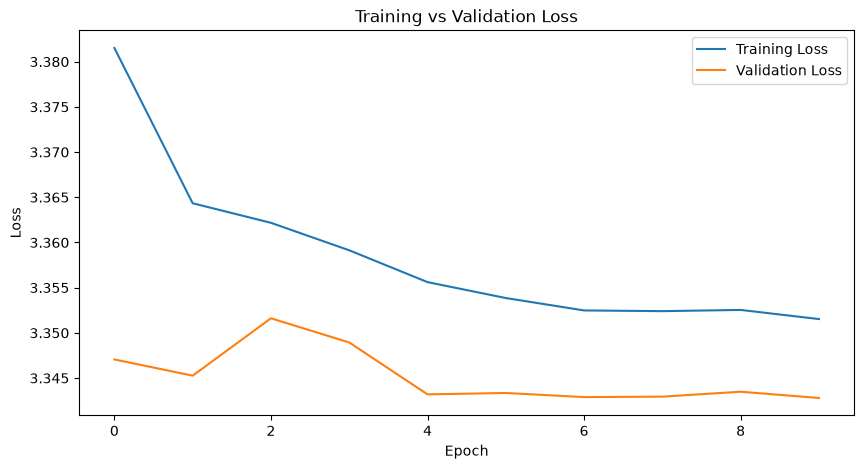

In [69]:
plt.figure(figsize=(10,5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

The loss curves indicate that the model training is stable, as neither training nor validation loss increases significantly during training. Both losses show a slight downward trend and remain close to each other, suggesting that the model is not overfitting. However, the improvement in loss is minimal, and when considered alongside the approximately 10% accuracy observed throughout training, the model is clearly underfitting. This means that the CNN has failed to learn meaningful features from the PlantVillage dataset and is performing only marginally better than random guessing.

In [70]:
# model evaluation
loss, accuracy = model.evaluate(
    validation_generator
)

print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy:.4f}")

340/340 ━━━━━━━━━━━━━━━━━━━━ 133s 392ms/step - accuracy: 0.1015 - loss: 3.3428
Validation Loss: 3.3428
Validation Accuracy: 0.1015


The final evaluation of the CNN model produced a validation accuracy of 10.15% and a validation loss of 3.3428. The low validation accuracy indicates that the model correctly classified only a small proportion of plant disease images, performing close to random guessing. Additionally, the high validation loss suggests that the model's predictions remained substantially different from the true class labels. Since both training and validation performance were similarly low, there is no evidence of overfitting. Instead, the results indicate severe underfitting, meaning that the model failed to learn meaningful feature representations from the PlantVillage dataset. 

In [71]:
# prediction and evaluation
validation_generator.reset()

pred_probs = model.predict(
    validation_generator
)

predicted_classes = np.argmax(
    pred_probs,
    axis=1
)

true_classes = validation_generator.classes

class_labels = list(
    validation_generator.class_indices.keys()
)


340/340 ━━━━━━━━━━━━━━━━━━━━ 112s 315ms/step


In [73]:
# classification report

print(
    classification_report(
        true_classes,
        predicted_classes,
        target_names=class_labels
    )
)

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.00      0.00      0.00       126
                                 Apple___Black_rot       0.00      0.00      0.00       124
                          Apple___Cedar_apple_rust       0.00      0.00      0.00        55
                                   Apple___healthy       0.00      0.00      0.00       329
                               Blueberry___healthy       0.00      0.00      0.00       300
          Cherry_(including_sour)___Powdery_mildew       0.00      0.00      0.00       210
                 Cherry_(including_sour)___healthy       0.00      0.00      0.00       170
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.00      0.00      0.00       102
                       Corn_(maize)___Common_rust_       0.00      0.00      0.00       238
               Corn_(maize)___Northern_Leaf_Blight       0.00      0.00      0.

c:\Users\grace\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\grace\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\grace\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

The classification report reveals extremely poor classification performance across the PlantVillage dataset. Most disease classes recorded precision, recall, and F1-scores of zero, indicating that the model failed to correctly identify samples belonging to those categories. The only class with non-zero performance was Orange Haunglongbing (Citrus Greening), which achieved a recall of 1.00 but a precision of only 0.10. This suggests that the model predicted the majority of images as Orange Haunglongbing regardless of their true class labels. Consequently, while all Citrus Greening images were identified, many images from other classes were incorrectly assigned to this category. 

The overall accuracy of 10% further confirms that the model performed only slightly better than random guessing. Additionally, the macro-average and weighted-average metrics remained close to zero, indicating poor generalization across classes. These results strongly suggest severe underfitting

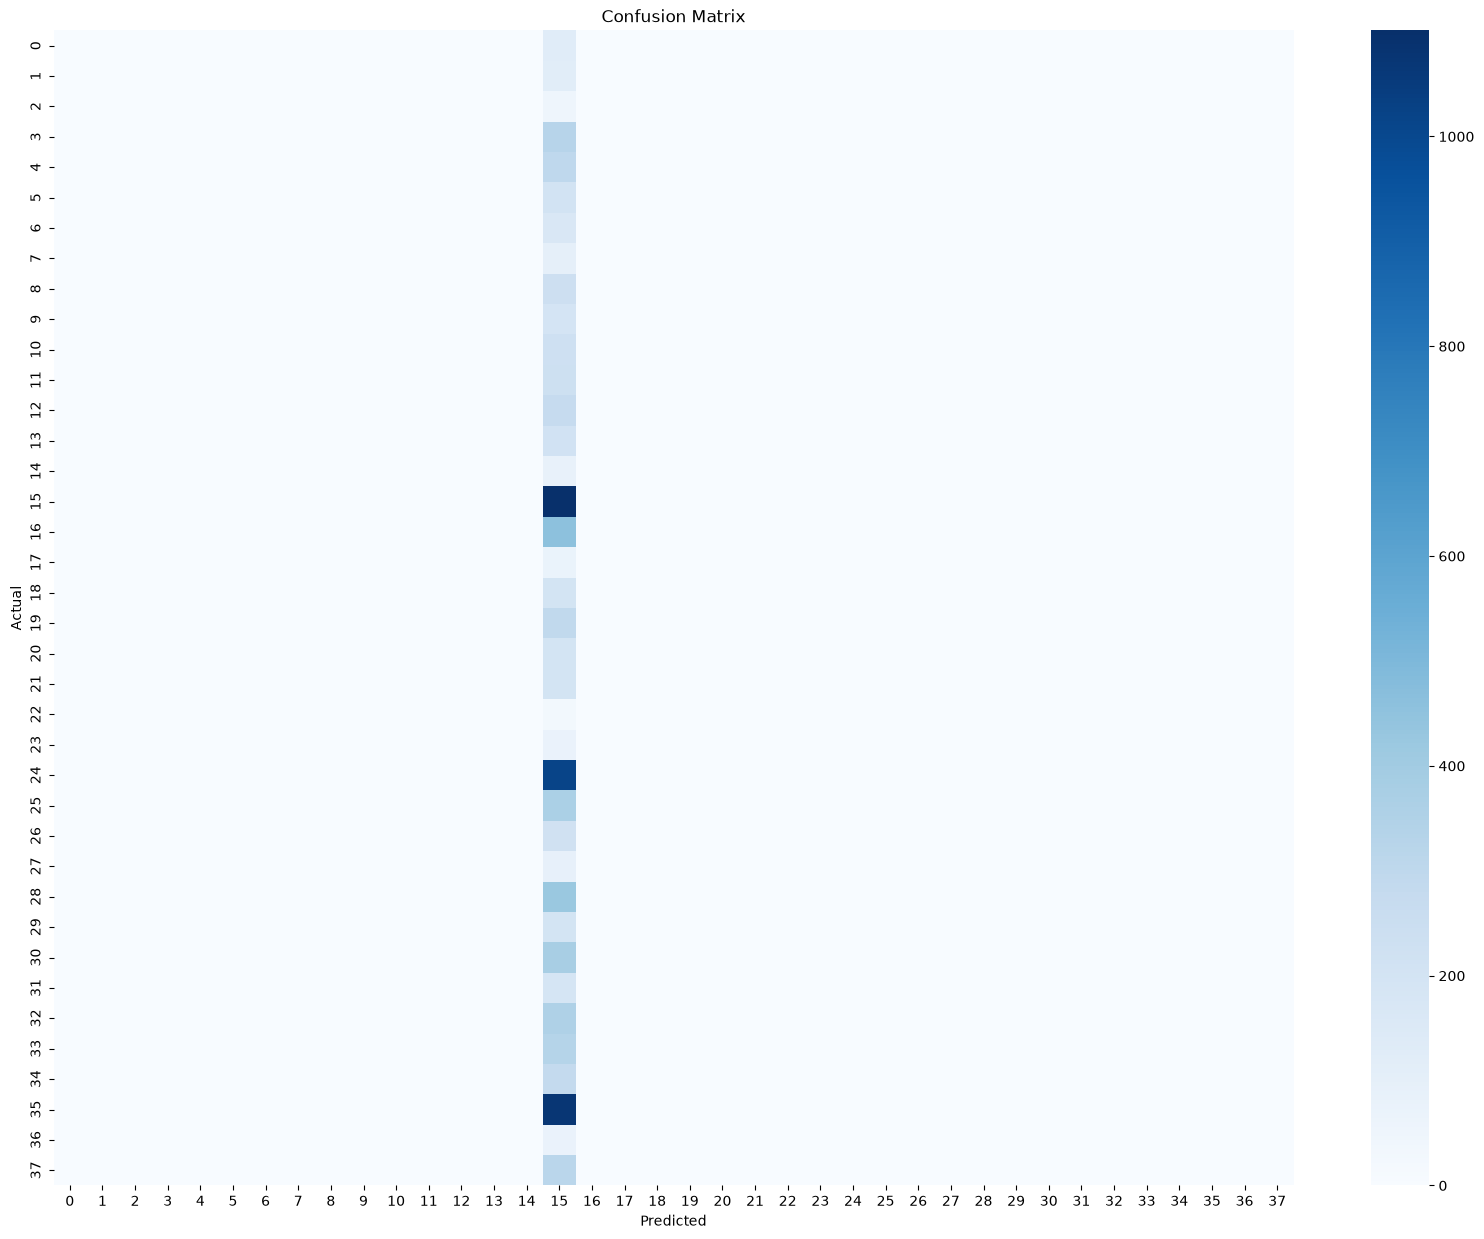

In [74]:
# confusion matrix
cm = confusion_matrix(
    true_classes,
    predicted_classes
)

plt.figure(figsize=(20,15))

sns.heatmap(
    cm,
    cmap='Blues'
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

The confusion matrix reveals that the CNN model failed to differentiate among the 38 plant disease classes. Rather than distributing predictions across multiple categories, the model concentrated nearly all predictions within a single class, represented by the prominent vertical band in the matrix. As a result, most disease categories were consistently misclassified as the same class.

 The absence of a strong diagonal pattern indicates that correct classifications were extremely limited. This observation is consistent with the classification report, where most classes achieved precision, recall, and F1-scores of zero. The results suggest that the model suffered from severe underfitting and effectively collapsed into predicting one dominant class for the majority of samples. Potential causes include class imbalance, label encoding errors, inadequate feature extraction, or inappropriate model architecture. Consequently, the model demonstrates poor discriminative capability and is unsuitable for reliable plant disease classification in its current state.

In [ ]:
#hyperparameter tuning
learning_rates = [0.001, 0.0005, 0.0001]

batch_sizes = [16, 32]

dropouts = [0.2, 0.3, 0.5]

In [ ]:
# save the best model and its hyperparameters

model.save(
    "plant_disease_classifier.keras"
)
